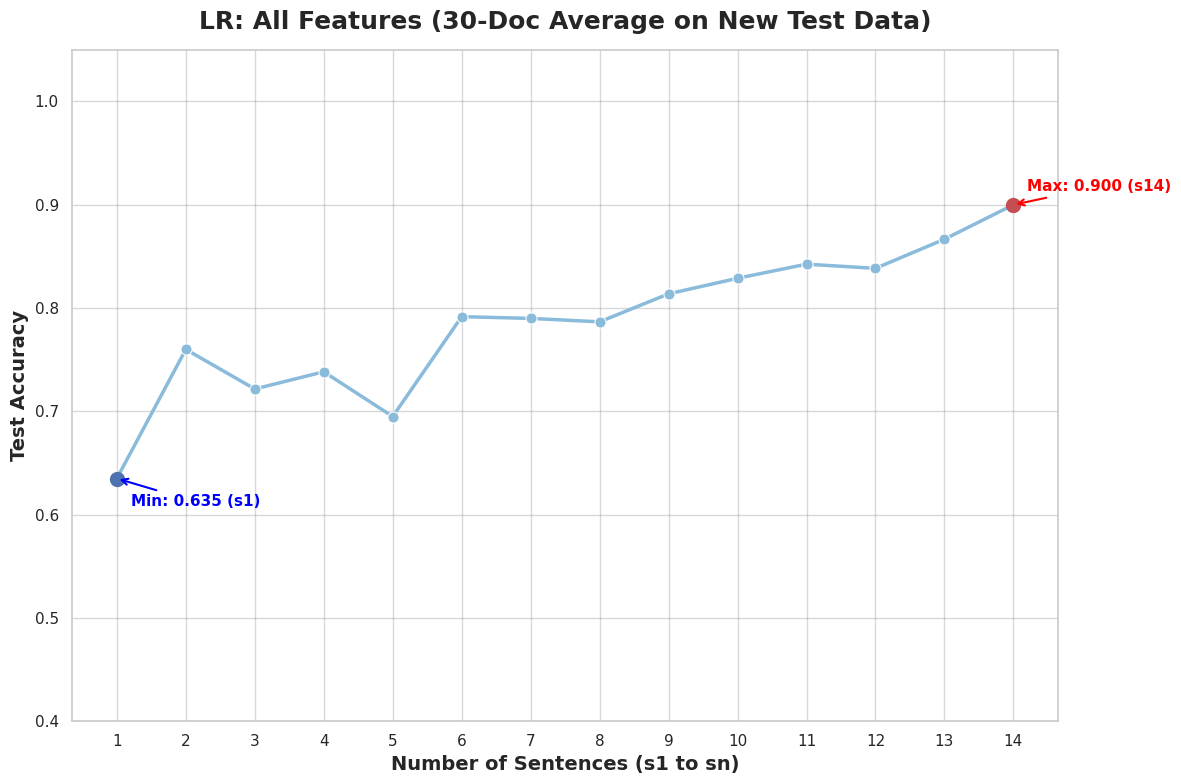

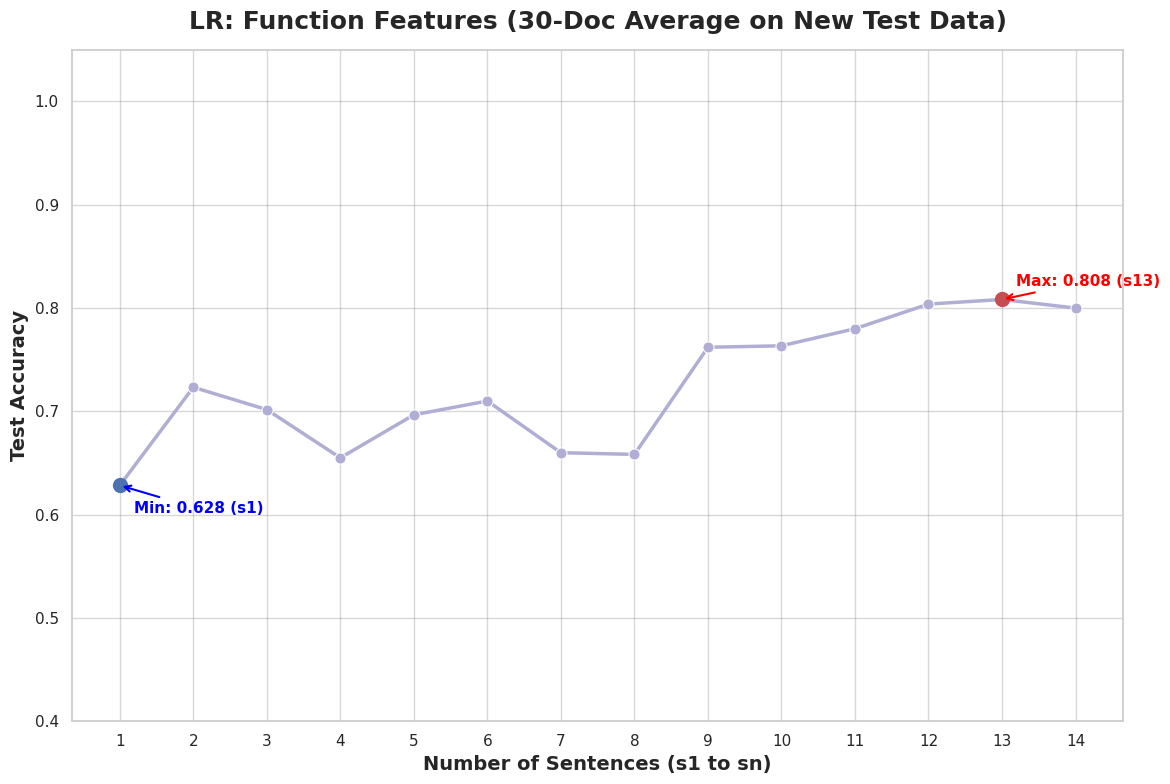

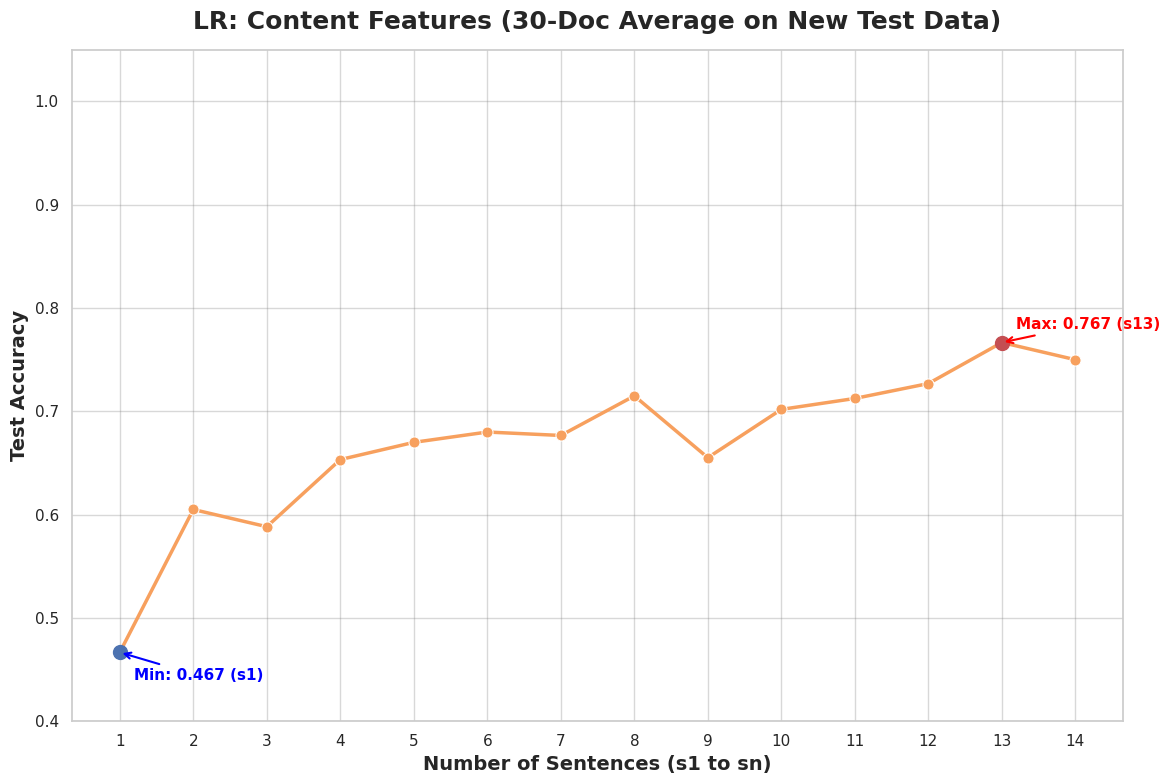

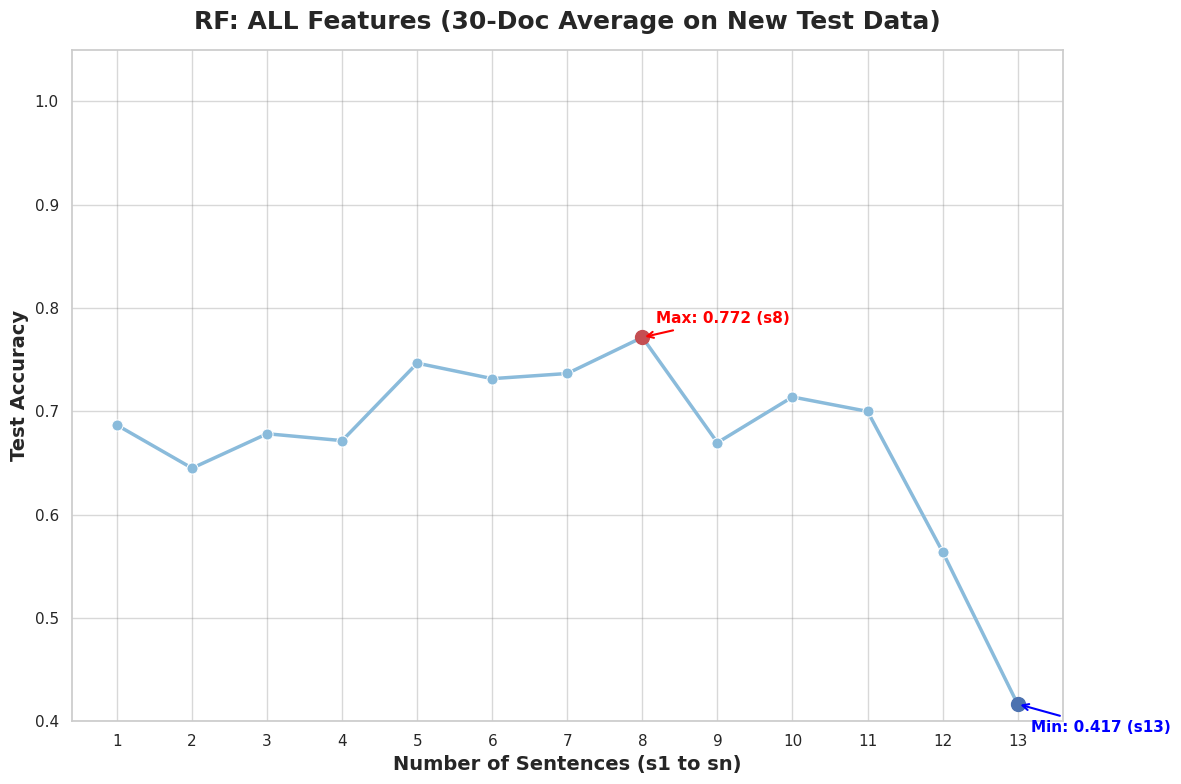

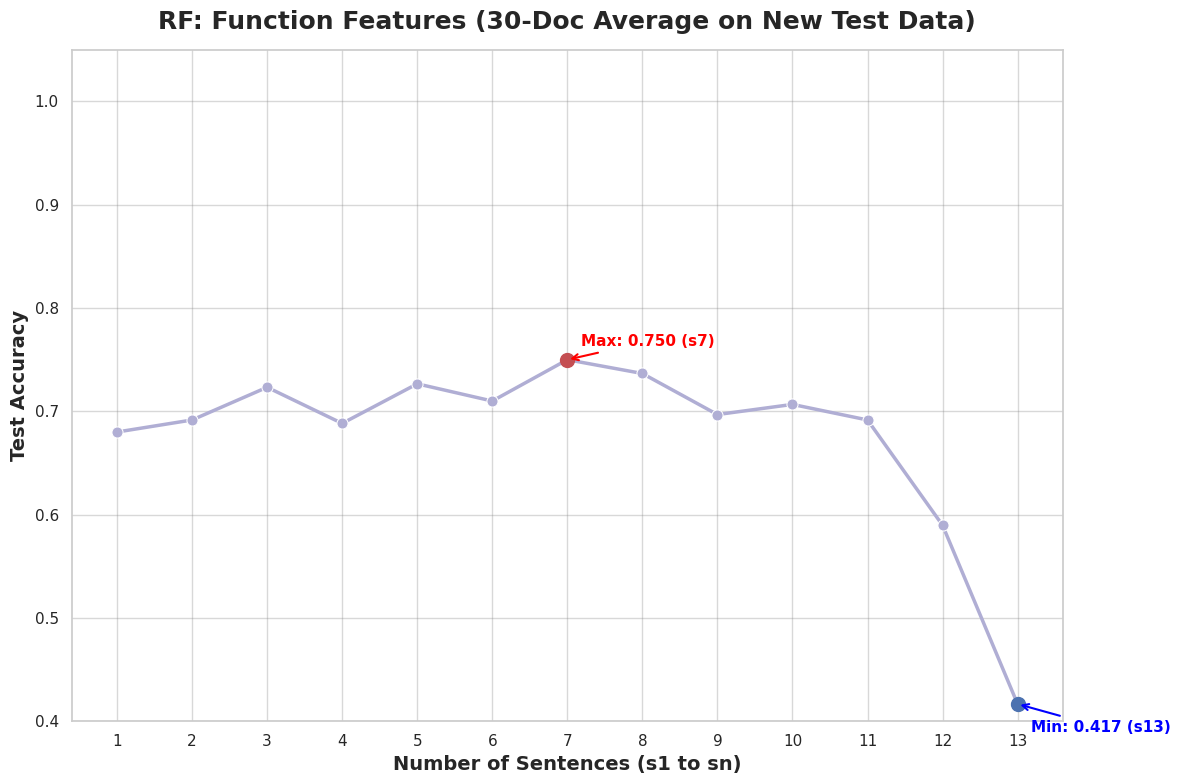

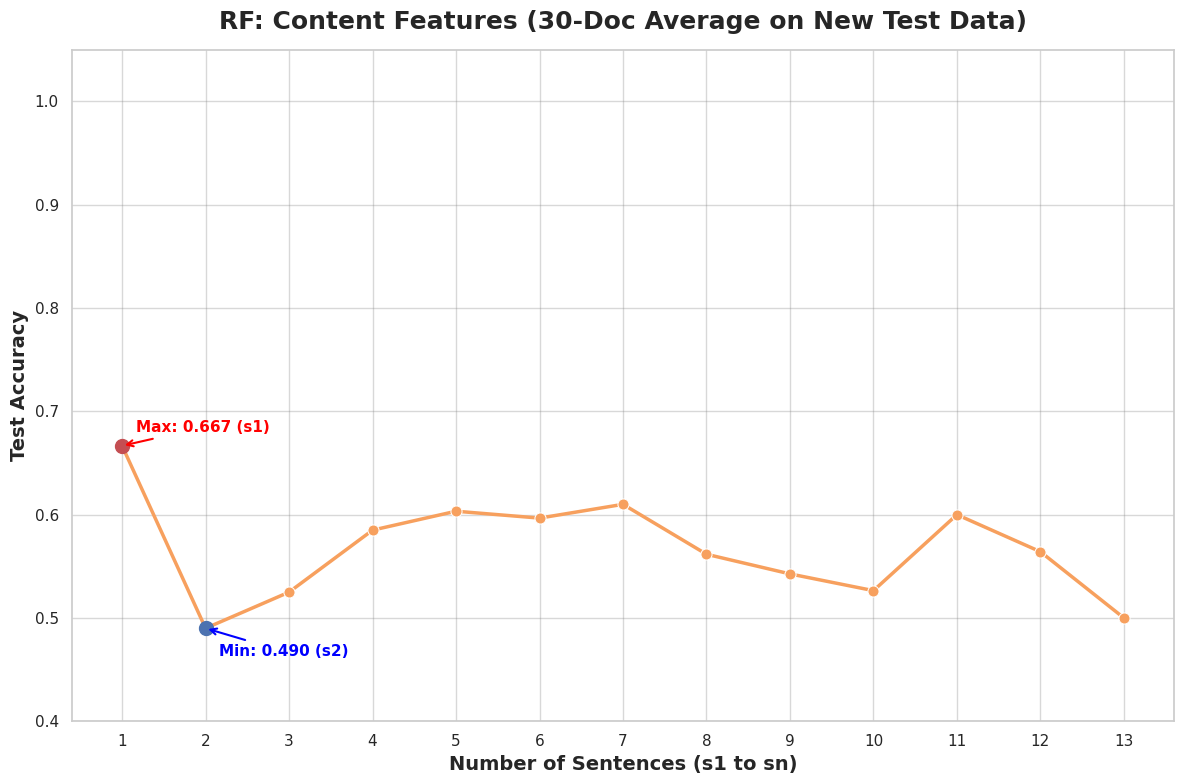

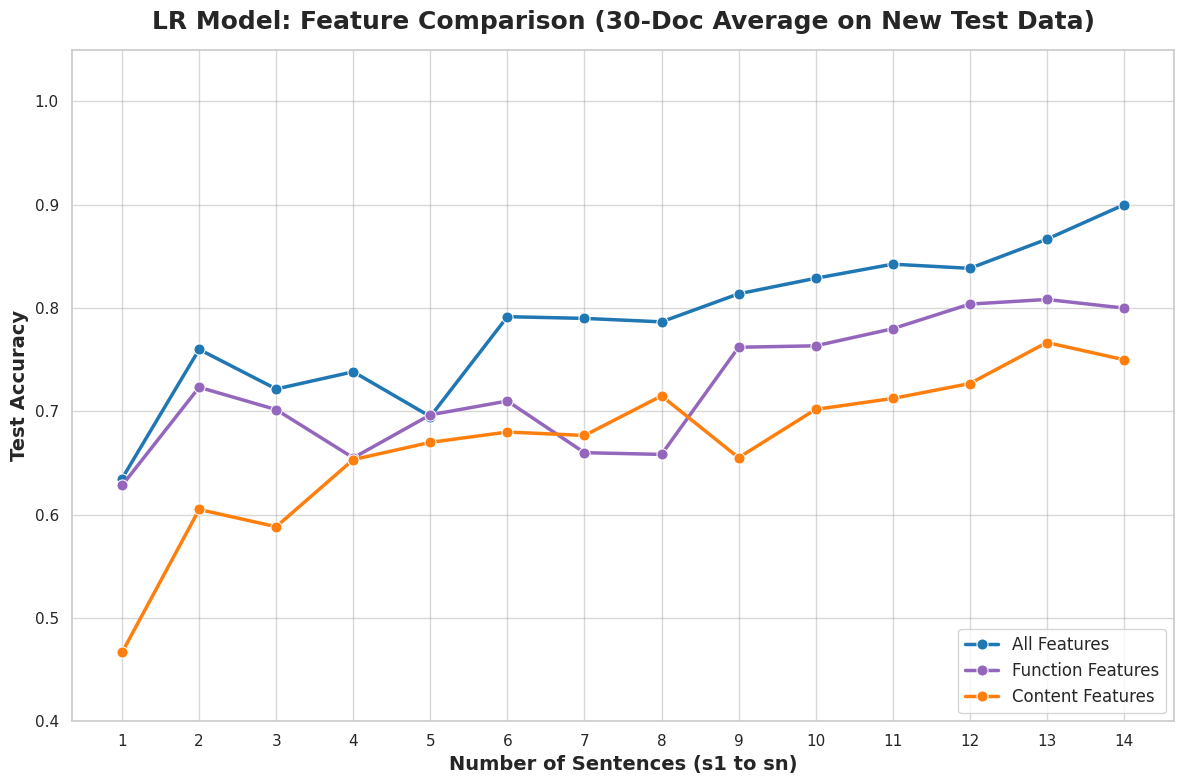

In [56]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. グラフの全体設定
# ==========================================
sns.set_theme(style="whitegrid")

# 描画対象のファイル設定 (テストデータ導入・30文書版のファイル名に合わせる)
target_files = {
    "test-doc_random_LR_All_all_increment_results_summary.csv": {"title": "LR: All Features", "color": "Blues_r"},
    "test-doc_random_LR_Function_all_increment_results_summary.csv": {"title": "LR: Function Features", "color": "Purples_r"},
    "test-doc_random_LR_Content_all_increment_results_summary.csv": {"title": "LR: Content Features", "color": "Oranges_r"},
    "random_RF_All_all_increment_results_summary.csv": {"title": "RF: ALL Features", "color": "Blues_r"},
    "random_RF_Function_all_increment_results_summary.csv": {"title": "RF: Function Features", "color": "Purples_r"},
    "random_RF_Content_all_increment_results_summary.csv": {"title": "RF: Content Features", "color": "Oranges_r"},
    # RF側も新しく実験を回したらここに追加してください
}

strong_palettes = {
    "Blues_r": "Blues_d", "Purples_r": "Purples_d", "Oranges_r": "Oranges_d",
    "Greens_r": "Greens_d", "YlOrBr_r": "YlOrBr_d", "Reds_r": "Reds_d"
}

# ==========================================
# 2. 1つずつ大きな画像として出力 (30文書の平均線版)
# ==========================================
for filename, config in target_files.items():
    if os.path.exists(filename):
        plt.figure(figsize=(12, 8), dpi=100)
        ax = plt.gca()
        df_res = pd.read_csv(filename)
        
        # 文数（sent_num）を抽出
        df_res["sent_num"] = df_res["used_sentences"].str.extract(r's1-s(\d+)').astype(int)

        # ★変更点：30文書すべてを平均対象にするため、1〜30番を含める
        df_res = df_res[df_res["increment_doc"].isin(range(1, 31))]
        
        # ----------------------------------------------------
        # ★追加: 平均値を計算して、最大値・最小値の座標を特定する
        # ----------------------------------------------------
        df_mean = df_res.groupby("sent_num")["accuracy"].mean().reset_index()
        max_row = df_mean.loc[df_mean["accuracy"].idxmax()]
        min_row = df_mean.loc[df_mean["accuracy"].idxmin()]
        # ----------------------------------------------------
        
        # errorbar=None で95%信頼区間を非表示
        sns.lineplot(
            data=df_res,
            x="sent_num",
            y="accuracy",
            marker="o",
            linewidth=2.5,
            markersize=8,
            color=sns.color_palette(strong_palettes.get(config["color"], config["color"]))[0],
            ax=ax,
            errorbar=None
        )
        
        # ----------------------------------------------------
        # ★追加: 最大値・最小値をグラフ上に描画・アノテーション
        # ----------------------------------------------------
        # 最大値（赤色の点とテキスト）
        ax.plot(max_row["sent_num"], max_row["accuracy"], "ro", markersize=10, label="Max")
        ax.annotate(
            f"Max: {max_row['accuracy']:.3f} (s{int(max_row['sent_num'])})",
            xy=(max_row["sent_num"], max_row["accuracy"]),
            xytext=(10, 10),                # テキストの表示位置を少しずらす
            textcoords="offset points",
            arrowprops=dict(arrowstyle="->", color="red", lw=1.5),
            color="red", fontweight="bold", fontsize=11
        )

        # 最小値（青色の点とテキスト）
        ax.plot(min_row["sent_num"], min_row["accuracy"], "bo", markersize=10, label="Min")
        ax.annotate(
            f"Min: {min_row['accuracy']:.3f} (s{int(min_row['sent_num'])})",
            xy=(min_row["sent_num"], min_row["accuracy"]),
            xytext=(10, -20),               # 被らないように下にずらす
            textcoords="offset points",
            arrowprops=dict(arrowstyle="->", color="blue", lw=1.5),
            color="blue", fontweight="bold", fontsize=11
        )
        # ----------------------------------------------------
        
        ax.set_title(f"{config['title']} (30-Doc Average on New Test Data)", fontsize=18, fontweight="bold", pad=15)
        ax.set_xlabel("Number of Sentences (s1 to sn)", fontsize=14, fontweight="bold")
        ax.set_ylabel("Test Accuracy", fontsize=14, fontweight="bold")
        ax.set_ylim(0.4, 1.05)
        ax.set_xticks(range(1, df_res["sent_num"].max() + 1))
        ax.grid(True, linestyle="-", alpha=0.3, color="gray")
        
        plt.tight_layout()
        save_name = filename.replace(".csv", "_average.png")
        plt.savefig(os.path.join("graphs", save_name), dpi=300, bbox_inches="tight")
        plt.show()
    else:
        print(f"Warning: {filename} not found.")

# ==========================================
# 3. LR / RF 別に All, Func, Cont を1つの図にまとめて出力
# ==========================================
models = ["LR", "RF"]
feature_types = ["All", "Function", "Content"]

combined_colors = {
    "All": "#1f77b4",       # 青
    "Function": "#9467bd",  # 紫
    "Content": "#ff7f0e"    # オレンジ
}

for model in models:
    plt.figure(figsize=(12, 8), dpi=100)
    ax = plt.gca()
    plotted_count = 0
    
    for feat in feature_types:
        filename = f"test-doc_random_{model}_{feat}_all_increment_results_summary.csv"
        
        if os.path.exists(filename):
            df_res = pd.read_csv(filename)
            df_res["sent_num"] = df_res["used_sentences"].str.extract(r's1-s(\d+)').astype(int)
            
            # ★ここでも30文書すべてを対象にする
            df_plot = df_res[df_res["increment_doc"].isin(range(1, 31))].copy()
            
            sns.lineplot(
                data=df_plot,
                x="sent_num",
                y="accuracy",
                marker="o",
                linewidth=2.5,
                markersize=8,
                color=combined_colors[feat],
                label=f"{feat} Features",
                errorbar=None,
                ax=ax
            )
            plotted_count += 1
            
    # グラフの装飾設定
    ax.set_title(f"{model} Model: Feature Comparison (30-Doc Average on New Test Data)", fontsize=18, fontweight="bold", pad=15)
    ax.set_xlabel("Number of Sentences (s1 to sn)", fontsize=14, fontweight="bold")
    ax.set_ylabel("Test Accuracy", fontsize=14, fontweight="bold")
    ax.set_ylim(0.4, 1.05)
    
    if plotted_count > 0:
        ax.set_xticks(range(1, df_plot["sent_num"].max() + 1))
        ax.grid(True, linestyle="-", alpha=0.3, color="gray")
        ax.legend(fontsize=12, loc="lower right", frameon=True)
        
        plt.tight_layout()
        save_name = f"random_{model}_combined_features_average.png"
        plt.savefig(os.path.join("graphs", save_name), dpi=300, bbox_inches="tight")
        plt.show()
    else:
        # RFなどファイルがまだない場合はスキップされます
        plt.close()